The last two chapters used `groupby()` in its simplest form: one grouping column, one
statistic, such as a continent's mean GDP to fill a gap in
[Data Cleaning](https://lizhen0909.github.io/stat303-1-sec20-coursebook/Data_cleaning.html) or a spending tertile's mean graduation rate in
[Data Preparation](https://lizhen0909.github.io/stat303-1-sec20-coursebook/Data_preparation.html). That one line is an instance of a general
pattern, and most summaries in data analysis follow it: split the rows into groups,
compute something within each group, and combine the results into a table.

This chapter makes that pattern a full tool. It covers counting by category, computing
several statistics at once with readable names, grouping by more than one column, and the
three things you can do with groups besides summarizing them: give every row a
group-level value, keep or drop whole groups, and take a few rows from each. Along the
way it asks a question every grouped summary raises: what exactly is being averaged?

By the end of this chapter you should be able to:

- Count rows by category with `value_counts()`, `crosstab()`, and `groupby().size()`, and count distinct values with `nunique()`.
- Describe `groupby()` as split–apply–combine, and summarize each group with one statistic, several statistics via `agg()`, or named results via named aggregation.
- Group by two columns, read and select from the resulting two-level index, and turn it back into ordinary columns with `reset_index()`.
- Decide whether a group mean should weight every row equally or by a size column such as population, and compute a weighted mean by group.
- Use `transform()` to give every row a group-level value, `filter()` to keep or drop whole groups, and `head()` or `sample()` to take rows from each group.

Complete the [practice activity](#practice-activity-split-summarize-and-compare)
after the worked examples.

## Set Up Your Chapter Files {#set-up-your-chapter-files}

Download the [Data Grouping and Aggregation practice kit](https://lizhen0909.github.io/stat303-1-sec20-coursebook/downloads/data-aggregation-practice.zip).
Extract `stat303-data-aggregation` inside the `chapters` folder of your `stat303-1`
course folder, open `stat303-1` in VS Code, and select the course environment. The
terminal opens in `stat303-1`, so move it into the kit with `cd chapters` and then
`cd stat303-data-aggregation` before you render the activity.

```text
stat303-1/
├── .venv/
├── assignments/
└── chapters/
    └── stat303-data-aggregation/
        ├── data_aggregation_examples.ipynb
        ├── activity12.ipynb
        ├── README.md
        └── data/
            └── gdp_lifeExpectancy.csv
```

Run `data_aggregation_examples.ipynb` for the lesson and complete `activity12.ipynb` for
your own activity report, with `stat303-data-aggregation` as the notebook working folder.
The data is read with the relative path `"data/gdp_lifeExpectancy.csv"`, so the notebooks
find it only when that folder is the working folder.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

**Environment check:** This chapter uses NumPy, pandas, matplotlib, and seaborn, all of
which are already in the course environment. If an import fails, check the selected
notebook kernel first: it must be the course environment, `stat303-1/.venv`, as in
[Project Environments, Packages, and File Paths](https://lizhen0909.github.io/stat303-1-sec20-coursebook/python_venv.html#install-packages-in-the-intended-environment).

## The data

This chapter uses country-level data on life expectancy, population, and GDP per capita,
recorded every five years from 1952 to 2007:

In [2]:
gdp = pd.read_csv("data/gdp_lifeExpectancy.csv")
print(gdp.shape)
gdp.head()

(1704, 6)


,country,continent,year,lifeExp,pop,gdpPercap
0,Afghanistan,Asia,1952,28.801,8425333,779.445314
1,Afghanistan,Asia,1957,30.332,9240934,820.853030
2,Afghanistan,Asia,1962,31.997,10267083,853.100710
3,Afghanistan,Asia,1967,34.020,11537966,836.197138
4,Afghanistan,Asia,1972,36.088,13079460,739.981106


Each row is one country in one year: `lifeExp` is life expectancy at birth in years,
`pop` is population, and `gdpPercap` is GDP per person in inflation-adjusted US dollars.
There are no missing values. With 142 countries and 12 years, the table has
142 × 12 = 1,704 rows, and that structure matters for every count below.

## Count by category

The simplest summary of a group is its size. Three tools count, and they differ in what
they count and how many columns they cross.

`value_counts()`, from [Pandas Fundamentals](https://lizhen0909.github.io/stat303-1-sec20-coursebook/pandas_fundamentals.html), counts the rows
in each category of one column:

In [3]:
gdp["continent"].value_counts()

continent
Africa      624
Asia        396
Europe      360
Americas    300
Oceania      24
Name: count, dtype: int64

These are **rows**, not countries: Africa has 624 rows because 52 countries are each
recorded in 12 years. To count distinct countries, use `nunique()`, the number of unique
values, within each continent:

In [4]:
gdp.groupby("continent")["country"].nunique()

continent
Africa      52
Americas    25
Asia        33
Europe      30
Oceania      2
Name: country, dtype: int64

Oceania is only 2 countries, Australia and New Zealand. Any comparison involving
"Oceania" is a comparison with two countries, which is worth knowing before reading a
summary table.

`crosstab()`, which drew the island-by-species counts in
[Data Visualization I](https://lizhen0909.github.io/stat303-1-sec20-coursebook/data_viz_1.html), counts combinations of two columns.
`margins=True` adds row and column totals labelled `All`:

In [5]:
pd.crosstab(gdp["continent"], gdp["year"], margins=True)

year,1952,1957,1962,1967,1972,1977,1982,1987,1992,1997,2002,2007,All
continent,,,,,,,,,,,,,
Africa,52,52,52,52,52,52,52,52,52,52,52,52,624
Americas,25,25,25,25,25,25,25,25,25,25,25,25,300
Asia,33,33,33,33,33,33,33,33,33,33,33,33,396
Europe,30,30,30,30,30,30,30,30,30,30,30,30,360
Oceania,2,2,2,2,2,2,2,2,2,2,2,2,24
All,142,142,142,142,142,142,142,142,142,142,142,142,1704


Every continent has the same number of rows in every year, so the data is **balanced**:
no country drops in or out over time. That is worth checking, because a continent
whose countries appear only in later years would show a "trend" made by the changing
membership rather than by change within countries.

| Question | Tool |
|---|---|
| How many rows in each category? | `df["col"].value_counts()` |
| How many distinct values in each group? | `df.groupby("g")["col"].nunique()` |
| How many rows in each combination of two columns? | `pd.crosstab(df["a"], df["b"])` |

## Split, apply, combine

Counting is one summary per group. Most questions need others — a mean, a median, a
total — and the tool that computes any of them by group is `groupby()`.

**Why group and aggregate?**

- **Summarize a large table.** Thousands of rows become one row per group that a reader
  can take in: total sales by region instead of every transaction.
- **Compare categories.** Patterns become visible when groups sit side by side: outcomes
  by treatment group, graduation rates by type of college, life expectancy by continent.
- **Follow groups over time.** Grouping by a time period — month, quarter, year — turns a
  stream of records into a trend you can plot.
- **Reduce complexity.** A summary at the right level answers the question without the
  noise of every individual row.

Every one of these works the same way. `groupby()` follows three steps, a pattern known
as **split–apply–combine**:

1. **Split** the rows into groups, one per distinct value of the grouping column.
2. **Apply** a computation to each group separately.
3. **Combine** the results into one Series or DataFrame, labelled by group.

![Split–apply–combine: six rows are split by `ID` into three groups, each group is summed, and the three sums are combined into one table.](https://lizhen0909.github.io/stat303-1-sec20-coursebook/images/group.png){width=560}

The diagram's six rows, as a DataFrame, give exactly its result:

In [6]:
toy = pd.DataFrame({"ID": ["X", "Y", "Z", "X", "Y", "Z"],
                    "Values": [10, 20, 30, 40, 50, 60]})
toy.groupby("ID")["Values"].sum()

ID
X    50
Y    70
Z    90
Name: Values, dtype: int64

Split puts rows with the same `ID` together (X holds 10 and 40), apply sums each group,
and combine stacks the three sums into one Series labelled by `ID`: X = 50, Y = 70,
Z = 90. The same three steps run on the GDP data, only with more rows.

`gdp.groupby("continent")` does only the first step. It returns a *GroupBy object* that
records which rows belong to which group but computes nothing until you ask:

In [7]:
by_continent = gdp.groupby("continent")
by_continent.size()

continent
Africa      624
Americas    300
Asia        396
Europe      360
Oceania      24
dtype: int64

`size()` counts the rows in each group, the same numbers as `value_counts()`. To see the
rows of one group, `get_group()` returns them as an ordinary DataFrame:

In [8]:
by_continent.get_group("Oceania").head()

,country,continent,year,lifeExp,pop,gdpPercap
60,Australia,Oceania,1952,69.12,8691212,10039.59564
61,Australia,Oceania,1957,70.33,9712569,10949.64959
62,Australia,Oceania,1962,70.93,10794968,12217.22686
63,Australia,Oceania,1967,71.10,11872264,14526.12465
64,Australia,Oceania,1972,71.93,13177000,16788.62948


The apply and combine steps happen when you pick a column and a statistic. This is the
form from the last two chapters, here giving the mean life expectancy in each continent
over all years:

In [9]:
by_continent["lifeExp"].mean().round(1)

continent
Africa      48.9
Americas    64.7
Asia        60.1
Europe      71.9
Oceania     74.3
Name: lifeExp, dtype: float64

Any statistic you have used on a whole column works per group: `mean()`, `median()`,
`std()`, `min()`, `max()`, `sum()`, `count()` (non-missing values), and `size()`
(all rows). Selecting a list of columns applies the statistic to each:

In [10]:
by_continent[["lifeExp", "gdpPercap"]].median().round(1)

,lifeExp,gdpPercap
continent,,
Africa,47.8,1192.1
Americas,67.0,5465.5
Asia,61.8,2646.8
Europe,72.2,12081.7
Oceania,73.7,17983.3


## Summarize with `agg()`

One statistic per group is often not enough. GDP per capita in 2007 shows why: a mean
alone hides how unequal the countries within a continent are. The rest of this section
works with that single year:

In [11]:
gdp_2007 = gdp[gdp["year"] == 2007]
gdp_2007.shape

(142, 6)

`agg()` takes a list of statistics and returns one column for each:

In [12]:
gdp_2007.groupby("continent")["gdpPercap"].agg(["mean", "median", "max"]).round(0)

,mean,median,max
continent,,,
Africa,3089.0,1452.0,13206.0
Americas,11003.0,8948.0,42952.0
Asia,12473.0,4471.0,47307.0
Europe,25054.0,28054.0,49357.0
Oceania,29810.0,29810.0,34435.0


In Asia the mean, about $12,500, is almost three times the median, about $4,500. Half
of Asian countries are below $4,500, and a few very rich ones pull the mean up: the same
right skew as expenditure in Data Cleaning. In Europe the median is *above* the mean,
because a handful of poorer countries pull the mean down. Reporting both shows what one
number alone would hide.

### Named aggregation

When the summary is going into a report, give each result a name. **Named aggregation**
passes one argument per output column, written as `name=(column, statistic)`. It also
lets each output come from a different column:

In [13]:
summary_2007 = gdp_2007.groupby("continent").agg(
    countries=("country", "nunique"),
    median_gdp=("gdpPercap", "median"),
    mean_life=("lifeExp", "mean"),
    total_pop=("pop", "sum"),
)
summary_2007.round(1)

,countries,median_gdp,mean_life,total_pop
continent,,,,
Africa,52,1452.3,54.8,929539692
Americas,25,8948.1,73.6,898871184
Asia,33,4471.1,70.7,3811953827
Europe,30,28054.1,77.6,586098529
Oceania,2,29810.2,80.7,24549947


Each argument name becomes a column. The result reads like the table you would put in a
report, and the code says exactly what each number is.

### Your own statistic

A statistic that pandas does not provide can be written as a function, and `agg()` will
apply it to each group. A lambda, from [Pandas Intermediate](https://lizhen0909.github.io/stat303-1-sec20-coursebook/pandas_intermediate.html),
is the short form. The range of GDP per capita within each continent:

In [14]:
gdp_2007.groupby("continent").agg(
    lowest_gdp=("gdpPercap", "min"),
    highest_gdp=("gdpPercap", "max"),
    gdp_range=("gdpPercap", lambda x: x.max() - x.min()),
).round(0)

,lowest_gdp,highest_gdp,gdp_range
continent,,,
Africa,278.0,13206.0,12929.0
Americas,1202.0,42952.0,41750.0
Asia,944.0,47307.0,46363.0
Europe,5937.0,49357.0,43420.0
Oceania,25185.0,34435.0,9250.0


The lambda receives each continent's `gdpPercap` values as a Series `x` and returns one
number. The same works for any rule you can write in a line: a percentile with
`lambda x: x.quantile(0.9)`, or the share above a threshold with `lambda x: (x > 10_000).mean()`.

| Goal | Code |
|---|---|
| One statistic | `df.groupby("g")["col"].mean()` |
| Several statistics for one column | `df.groupby("g")["col"].agg(["mean", "median"])` |
| Named results, any columns | `df.groupby("g").agg(name=("col", "mean"), ...)` |
| Your own statistic | `name=("col", lambda x: x.max() - x.min())` |

## Group by two columns

Grouping by continent alone mixes 55 years together. To follow each continent over time,
group by continent *and* year by passing a list:

In [15]:
life_by_year = gdp.groupby(["continent", "year"])["lifeExp"].mean().round(1)
life_by_year.head(14)

continent  year
Africa     1952    39.1
           1957    41.3
           1962    43.3
           1967    45.3
           1972    47.5
           1977    49.6
           1982    51.6
           1987    53.3
           1992    53.6
           1997    53.6
           2002    53.3
           2007    54.8
Americas   1952    53.3
           1957    56.0
Name: lifeExp, dtype: float64

The result has one row per continent–year combination, 5 × 12 = 60 in all, and a
**two-level index** (also called a MultiIndex): continent on the outer level and year on
the inner. `.loc[]` selects from it. One label selects a whole outer group; a tuple
selects a single row:

In [16]:
print(life_by_year.loc["Oceania"])
print("Africa, 2007:", life_by_year.loc[("Africa", 2007)])

year
1952    69.3
1957    70.3
1962    71.1
1967    71.3
1972    71.9
1977    72.9
1982    74.3
1987    75.3
1992    76.9
1997    78.2
2002    79.7
2007    80.7
Name: lifeExp, dtype: float64
Africa, 2007: 54.8


For most further work — plotting, filtering, merging — ordinary columns are easier than a
two-level index. `reset_index()`, from Pandas Fundamentals, moves the index levels back
into columns:

In [17]:
life_trend = life_by_year.reset_index()
life_trend.head()

,continent,year,lifeExp
0,Africa,1952,39.1
1,Africa,1957,41.3
2,Africa,1962,43.3
3,Africa,1967,45.3
4,Africa,1972,47.5


In that form the summary goes straight into a seaborn plot from
[Data Visualization I](https://lizhen0909.github.io/stat303-1-sec20-coursebook/data_viz_1.html). The `ax.legend(loc="upper left", ncols=5)` line
lays the legend out in one row above the lines, using the `ncols=` from the shared legend
in [Data Visualization II](https://lizhen0909.github.io/stat303-1-sec20-coursebook/data_viz_2.html), so it covers none of the data:

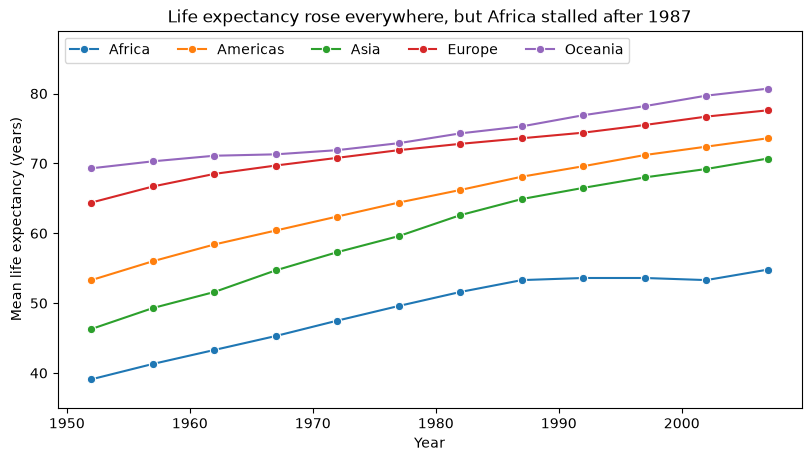

In [18]:
fig, ax = plt.subplots(figsize=(8, 4.5), layout="constrained")
sns.lineplot(data=life_trend, x="year", y="lifeExp", hue="continent", marker="o", ax=ax)
ax.set(xlabel="Year", ylabel="Mean life expectancy (years)", ylim=(35, 89),
       title="Life expectancy rose everywhere, but Africa stalled after 1987")
ax.legend(title=None, loc="upper left", ncols=5)   # one row, clear of the lines
plt.show()

Every continent gained, and Africa's gain stalled from the late 1980s to the early 2000s
while the others kept rising. Turning a grouped Series into a wide table, with one column
per year, is reshaping, which is the subject of the next chapter.

## What a group mean averages

Each value in that plot is a mean over **countries**: Mongolia and China count equally
toward Asia's figure. That answers the question "what was life expectancy in a typical
Asian country?" It does not answer "how long did a typical person in Asia live?", because
China and India hold most of Asia's people.

The second question needs a **weighted mean**, in which each country counts in proportion
to its population:

$$\text{weighted mean} = \frac{\sum (\text{pop} \times \text{lifeExp})}{\sum \text{pop}}$$

`groupby()` can compute both sums at once. Make a column of the products, sum it and
`pop` by group, and divide:

In [19]:
gdp["pop_x_life"] = gdp["pop"] * gdp["lifeExp"]
sums = gdp.groupby(["continent", "year"])[["pop_x_life", "pop"]].sum()
weighted_life = sums["pop_x_life"] / sums["pop"]

asia = pd.DataFrame({
    "per country (unweighted)": life_by_year.loc["Asia"],
    "per person (weighted by population)": weighted_life.loc["Asia"],
}).round(1)
asia.loc[[1952, 1982, 2007]]

,per country (unweighted),per person (weighted by population)
year,,
1952,46.3,42.9
1982,62.6,61.6
2007,70.7,69.4


In 1952 the typical Asian *country* had a life expectancy of 46.3 years, but the typical
Asian *person* only 42.9, because the most populous countries had some of the lowest
values. Dividing two group sums keeps everything aligned by the shared continent–year
index, so each weighted mean uses its own group's numbers.

Plotting both versions over every year shows something the three rows hide.
`asia.plot()`, the pandas plotting from Data Visualization I, draws one line per column
against the index:

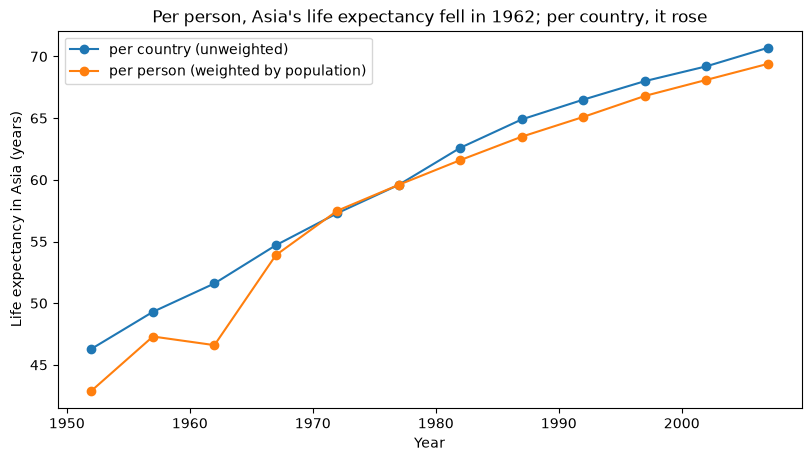

In [20]:
fig, ax = plt.subplots(figsize=(8, 4.5), layout="constrained")
asia.plot(ax=ax, marker="o")
ax.set(xlabel="Year", ylabel="Life expectancy in Asia (years)",
       title="Per person, Asia's life expectancy fell in 1962; per country, it rose")
plt.show()

Between 1957 and 1962 the per-country line keeps rising, but the per-person line *falls*,
from 47.3 to 46.6 years, and the gap between them jumps to 5 years. The cause is one
country. China's life expectancy dropped from 50.5 years in 1957 to 44.5 in 1962, the
years of the famine of 1959–1961, and China held 39% of Asia's people. In a per-country
mean China is one country in 33, so the drop barely registers; weighted by population, it
dominates.

Neither mean is wrong; they answer different questions. When you report a group mean,
say which one it is — per country, per person, per college — because the reader cannot
tell from the number.

## Give every row a group value: `transform()`

Summaries return one row per group. Sometimes you want the group value on **every row**
instead, to compare each row with its own group. Data Cleaning used `transform("mean")`
to fill a missing GDP with its continent's mean; the same tool answers "how does each
country compare with its continent in the same year?":

In [21]:
continent_year_mean = gdp.groupby(["continent", "year"])["gdpPercap"].transform("mean")
gdp["gdp_vs_continent"] = gdp["gdpPercap"] / continent_year_mean

gdp.loc[gdp["year"] == 2007,
        ["country", "continent", "gdpPercap", "gdp_vs_continent"]].sort_values(
    "gdp_vs_continent", ascending=False).head().round(2)

,country,continent,gdpPercap,gdp_vs_continent
551,Gabon,Africa,13206.48,4.28
167,Botswana,Africa,12569.85,4.07
491,Equatorial Guinea,Africa,12154.09,3.93
1619,United States,Americas,42951.65,3.90
911,Libya,Africa,12057.50,3.90


`transform("mean")` returns 1,704 values, one per row in the original order, so it can
be divided into `gdpPercap` directly. A value of 2 means twice the continent's mean in
that year. Any statistic name works in `transform()`, as does a lambda.

The table says Gabon's GDP per capita in 2007 was 4.28 times Africa's mean: oil revenue
spread over a small population, in a continent where the typical economy is far poorer.
Four of the top five are African for the same reason. A few such countries are also what
puts Africa's mean GDP per capita ($3,089 in 2007) at about twice its median ($1,452).

## Keep or drop whole groups: `filter()`

`filter()` tests each group against a rule and keeps **all** the rows of the groups that
pass. The rule is a function that receives one group as a DataFrame and returns `True` or
`False`. Which countries gained more than 30 years of life expectancy between 1952 and
2007?

In [22]:
big_gainers = gdp.groupby("country").filter(
    lambda g: g["lifeExp"].max() - g["lifeExp"].min() > 30
)
print(big_gainers["country"].nunique(), "countries")
big_gainers["country"].unique()

9 countries


<StringArray>
[         'Indonesia',        'Korea, Rep.',              'Libya',
          'Nicaragua',               'Oman',       'Saudi Arabia',
            'Vietnam', 'West Bank and Gaza',        'Yemen, Rep.']
Length: 9, dtype: str

Every row of those 9 countries is kept, all 12 years each, so the result can be plotted
or summarized like the full data. A Boolean mask on rows, by contrast, tests each row on
its own:

In [23]:
over_70 = gdp[gdp["lifeExp"] > 70]
print(len(over_70), "rows from", over_70["country"].nunique(), "countries")

493 rows from 84 countries


The mask keeps every country-year above 70, so most of those 84 countries appear only
for their later years. Use a mask for a rule about a row, and `filter()` for a rule about
a group as a whole.

## Take rows from each group: `head()` and `sample()`

To take the top rows of each group, sort first, then take `head()` within each group:

In [24]:
(gdp[gdp["year"] == 2007]
    .sort_values("lifeExp", ascending=False)
    .groupby("continent")
    .head(2)[["continent", "country", "lifeExp"]])

,continent,country,lifeExp
803,Asia,Japan,82.603
671,Asia,"Hong Kong, China",82.208
695,Europe,Iceland,81.757
1487,Europe,Switzerland,81.701
71,Oceania,Australia,81.235
251,Americas,Canada,80.653
1103,Oceania,New Zealand,80.204
359,Americas,Costa Rica,78.782
1271,Africa,Reunion,76.442
911,Africa,Libya,73.952


That is the two longest-lived countries of each continent in 2007. The expression is
wrapped in parentheses so that each step can sit on its own line.

`sample()` draws rows at random within each group. A plain random sample of the whole
table reflects the continents' sizes, so Oceania, with 24 rows, would barely appear. A
**stratified sample** takes the same number from every group instead:

In [25]:
stratified = gdp.groupby("continent").sample(n=24, random_state=303)
stratified["continent"].value_counts()

continent
Africa      24
Americas    24
Asia        24
Europe      24
Oceania     24
Name: count, dtype: int64

`random_state=303` fixes the random draw, so the sample is the same every time the cell
runs. Here `n=24` takes every Oceania row, since that is all there is.

| Goal | Result | Code |
|---|---|---|
| One row per group | Summary table | `df.groupby("g").agg(...)` |
| Group value on every row | Same rows, new column | `df.groupby("g")["col"].transform("mean")` |
| Keep whole groups that pass a rule | Fewer rows, whole groups | `df.groupby("g").filter(lambda g: ...)` |
| First rows of each group | A few rows per group | `df.sort_values(...).groupby("g").head(n)` |
| Random rows from each group | A few rows per group | `df.groupby("g").sample(n=..., random_state=...)` |

## Summary Cheat Sheet {#summary-cheat-sheet}

**Counting.**

| Goal | Code |
|---|---|
| Rows per category | `df["col"].value_counts()` |
| Rows per group | `df.groupby("g").size()` |
| Distinct values per group | `df.groupby("g")["col"].nunique()` |
| Rows per combination of two columns | `pd.crosstab(df["a"], df["b"], margins=True)` |

**Summarizing.**

| Goal | Code |
|---|---|
| One statistic per group | `df.groupby("g")["col"].mean()` |
| Several statistics | `df.groupby("g")["col"].agg(["mean", "median", "max"])` |
| Named results | `df.groupby("g").agg(name=("col", "mean"), other=("col2", "sum"))` |
| Your own statistic | `name=("col", lambda x: x.max() - x.min())` |
| Group by two columns | `df.groupby(["a", "b"])["col"].mean()` |
| Select from a two-level index | `s.loc["outer"]`, `s.loc[("outer", inner)]` |
| Back to ordinary columns | `s.reset_index()` |
| Weighted mean by group | sum `w * x` and `w` by group, then divide |

**Beyond summaries.**

| Goal | Code |
|---|---|
| Group value on every row | `df.groupby("g")["col"].transform("mean")` |
| Keep whole groups by a rule | `df.groupby("g").filter(lambda g: ...)` |
| Top rows per group | `df.sort_values("col").groupby("g").head(n)` |
| Stratified random sample | `df.groupby("g").sample(n=..., random_state=...)` |

The rule to remember: **before you report a group summary, know how many rows and
distinct units are in each group, and what each one counts for.**

## Practice Activity: Split, Summarize, and Compare {#practice-activity-split-summarize-and-compare}

**Goal:** Summarize one dataset by group in several ways, and say what each summary counts.

**File:** `activity12.ipynb` from the [practice kit](https://lizhen0909.github.io/stat303-1-sec20-coursebook/downloads/data-aggregation-practice.zip).

**Submit:** `activity12.html` through the final upload question in the Data Grouping and Aggregation Canvas quiz.

**This section contains the complete activity instructions.** The starter loads the data and supplies spaces to record your work. Open `activity12.ipynb` from the folder prepared in [Set Up Your Chapter Files](#set-up-your-chapter-files), using the same project environment. The worked examples above are preparation, not additional submission requirements.

The starter loads `gdp` from the kit's `data/` folder and makes `gdp_1977`, the rows for 1977.

### A. Count Before You Compare {.unnumbered}

- Replace `Your Name` in the opening Raw cell's `author` field. Run the setup cell; it must report the shapes `(1704, 6)` and `(142, 6)`.
- Report the number of rows and the number of distinct countries in each continent, and explain in one sentence why the two counts differ.
- Name the continent you would be most cautious about comparing with the others, and say why.

### B. A Summary Table With Named Columns {.unnumbered}

- Using `gdp_1977`, build one table with named aggregation that gives, for each continent, the number of countries, the mean and median of `gdpPercap`, and the total population.
- Name the continent whose mean and median GDP per capita differ the most, and explain what that difference says about the countries in it.

### C. Per Country or Per Person? {.unnumbered}

- For each continent in 1977, compute mean life expectancy twice: once with every country counting equally, and once weighted by population.
- Name the continent where the two differ most, and explain in one or two sentences why weighting changes it in that direction.

### D. Every Row Against Its Group, and Whole Groups by a Rule {.unnumbered}

- Use `transform()` to add a column giving each country's life expectancy minus its continent's mean in the same year. Show the five countries furthest below their continent's mean in 1977.
- Use `filter()` to keep the countries whose population more than tripled between 1952 and 2007, and report how many there are.

### Render and Submit {.unnumbered}

Restart the kernel, run all cells in order, resolve unexpected errors, and save. Include your outputs and explanations for A–D, and a short Markdown completion note. From `stat303-data-aggregation` in the terminal, run:

```text
quarto render activity12.ipynb --to html
```

Follow the [Quarto refresher](https://lizhen0909.github.io/stat303-1-sec20-coursebook/vscode_setup.html#render-and-submit-with-quarto): inspect the HTML and a copy opened outside the project folder, and confirm that every output appears and your name is on the report. Upload only `activity12.html` to the Data Grouping and Aggregation Canvas quiz; keep your notebook locally.

**HTML grading (16 points):** row and country counts with the explanation and the cautious comparison (4); the named-aggregation table and the mean–median explanation (4); unweighted and weighted means with the explanation (4); the `transform()` column with its five countries, and the `filter()` count (3); name, readable report, and completion note (1).

## Extended Practice {#extended-practice}

These longer exercises are additional practice, not requirements for the Canvas quiz.
Work in a separate notebook beside your activity and load the data the way the chapter
does. Include your code, outputs, and explanations.

### The World Over Time, Two Ways

Compute world life expectancy for every year twice, per country and per person, and plot
both lines on one figure. When are the two furthest apart, and which countries drive the
gap? Repeat for GDP per capita.

### Correlation Within Each Continent

For each continent, compute the correlation between `lifeExp` and `gdpPercap` over all
years. Unlike `agg()`, which hands its function one column of each group, `apply()`
hands it the whole group as a DataFrame, so the function can use two columns at once:
`gdp.groupby("continent")[["lifeExp", "gdpPercap"]].apply(lambda g: g["lifeExp"].corr(g["gdpPercap"]))`.
Then repeat with `np.log(gdpPercap)`. Which continents change most, and why might a log
make the relationship more linear?

### Biggest Gains and Losses

For each country, compute the change in life expectancy from each survey year to the
next. Which country had the largest single five-year drop, and when? The hint is
[`diff()`](https://pandas.pydata.org/docs/reference/api/pandas.core.groupby.DataFrameGroupBy.diff.html),
which subtracts each value from the one after it:
`gdp.sort_values(["country", "year"]).groupby("country")["lifeExp"].diff()`. Grouping by
`country` means one country's last year is never compared with the next country's first.

### A Fair Sample

Draw a stratified sample of 10 countries per continent (all 12 years of each), rather
than 10 rows. Hint: sample from the 2007 rows to choose the countries, then keep every
row for those countries with `isin()`. Compare the mean life expectancy of your sample
with the full data's.

## Before You Move On {#before-you-move-on}

The habit to carry forward is knowing what a group summary counts. A count of rows is not
a count of units; a mean over countries is not a mean over people; a continent with two
countries is not comparable, on equal terms, with a continent of fifty. None of these
produces an error, and every one changes what a summary table says.

The other habit is choosing the operation by the shape of the result you need: one row
per group to summarize, every row with a group value to compare, whole groups to keep or
drop, or a few rows from each group to sample.

For any grouped summary you make or read, you should be able to answer five questions:

1. What are the groups, and how many rows and distinct units does each contain?
2. Which statistic summarizes each group, and why that one?
3. Does each row count equally, and should it?
4. Is the data balanced across groups and over time?
5. Did you need one row per group, or a group value on every row?

Continue to [Data Reshaping](https://lizhen0909.github.io/stat303-1-sec20-coursebook/Data_reshaping.html), where grouped results like these are
rearranged between long and wide tables.

References: [pandas: group by (split-apply-combine)](https://pandas.pydata.org/docs/user_guide/groupby.html),
[`DataFrame.groupby`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.groupby.html),
[`DataFrameGroupBy.agg`](https://pandas.pydata.org/docs/reference/api/pandas.core.groupby.DataFrameGroupBy.agg.html),
[`DataFrameGroupBy.transform`](https://pandas.pydata.org/docs/reference/api/pandas.core.groupby.DataFrameGroupBy.transform.html),
[`DataFrameGroupBy.filter`](https://pandas.pydata.org/docs/reference/api/pandas.core.groupby.DataFrameGroupBy.filter.html),
[`DataFrameGroupBy.sample`](https://pandas.pydata.org/docs/reference/api/pandas.core.groupby.DataFrameGroupBy.sample.html),
[`pd.crosstab`](https://pandas.pydata.org/docs/reference/api/pandas.crosstab.html),
and [`DataFrame.reset_index`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.reset_index.html).